In [1]:
import json
from pathlib import Path

import cv2
import numpy as np
from IPython.display import Image, display

# Grid step in pixels. Layout 1 prints a 3 m x 3 m box that measures 99 px, so 1 m is 33 px.
# Layout 2 prints no scale, so its grid is only a visual guide of about one booth tile.
# Layout 3 prints a 2 m dimension over a 67 px booth, so 1 m is 33 px.
GRID_PX = {"../output/swift4/plan1": 33, "../output/swift4/plan2": 60, "../output/swift4/plan3": 33}

# BGR colour and line width for the classes swift4 finds outside the legend; -1 fills the box.
OUTSIDE = {"wall": ((0, 0, 0), 3), "door": ((0, 160, 0), 4), "pillar": ((90, 90, 90), -1), "object": ((0, 140, 255), 2)}


In [2]:
def render(out_dir, suggested=False):
    layout = json.loads((Path(out_dir) / "layout.json").read_text())
    print(json.dumps(layout["report"], indent=2))

    W, H = layout["image"]["width"], layout["image"]["height"]
    step = GRID_PX.get(out_dir, 60 if "2" in out_dir else 33)
    canvas = np.full((H, W, 3), 255, np.uint8)
    for i, pos in enumerate(range(0, max(W, H), step)):
        shade = (170, 170, 170) if i % 5 == 0 else (225, 225, 225)
        cv2.line(canvas, (pos, 0), (pos, H), shade, 1)
        cv2.line(canvas, (0, pos), (W, pos), shade, 1)

    for it in layout["items"]:
        x, y, w, h = it["box"]
        if it["class"] in OUTSIDE:
            color, width = OUTSIDE[it["class"]]
            if it.get("polygon") and len(it["polygon"]) >= 3:
                pts = [np.array(it["polygon"], np.int32)]
                if width < 0:
                    cv2.fillPoly(canvas, pts, color)
                else:
                    cv2.polylines(canvas, pts, True, color, width)
            else:
                cv2.rectangle(canvas, (x, y), (x + w, y + h), color, width)
            continue
        outline = tuple(it["fill_rgb"][::-1])
        if min(outline) > 235:  # near-white legend rows would vanish on the white canvas
            outline = (160, 160, 160)
        if it.get("polygon"):  # sloped booths keep their slanted edges
            cv2.polylines(canvas, [np.array(it["polygon"], np.int32)], True, outline, 3)
        else:
            cv2.rectangle(canvas, (x, y), (x + w, y + h), outline, 3)

        text = it.get("id")
        color = (0, 0, 0)
        if suggested and it.get("suggested_id"):
            text = it["suggested_id"]
            color = (220, 100, 30)  # blue in BGR
        elif text is None:
            if it.get("suggested_id"):
                text = it["suggested_id"]
                color = (220, 100, 30)  # blue in BGR
            else:
                text = "?"
                color = (30, 30, 220)  # red in BGR

        cv2.putText(canvas, text, (x + 6, y + h // 2 + 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

    cv2.imwrite(str(Path(out_dir) / "render.png"), canvas)
    display(Image(data=cv2.imencode(".png", canvas)[1].tobytes(), width=1000))


{
  "duplicate_ids": [
    "D6"
  ],
  "gaps_in_numbering": {
    "C": [
      6
    ]
  },
  "ids_read": 154,
  "items_per_class": {
    "Blocked": 3,
    "Booth A": 9,
    "Booth B": 26,
    "Booth C": 21,
    "Booth D": 8,
    "Booth F": 27,
    "Booth G": 25,
    "Booth H": 18,
    "Booth J": 5,
    "Booth K": 10,
    "ENTRANCE": 9,
    "Large booth X": 3,
    "Large booth XX": 3,
    "Stage": 2,
    "door": 4,
    "object": 216,
    "wall": 28
  },
  "items_without_id": 263,
  "max_number_per_prefix": {
    "A": 9,
    "B": 26,
    "C": 21,
    "D": 8,
    "F": 27,
    "G": 25,
    "H": 18,
    "J": 4,
    "K": 10,
    "X": 3,
    "XX": 3
  }
}


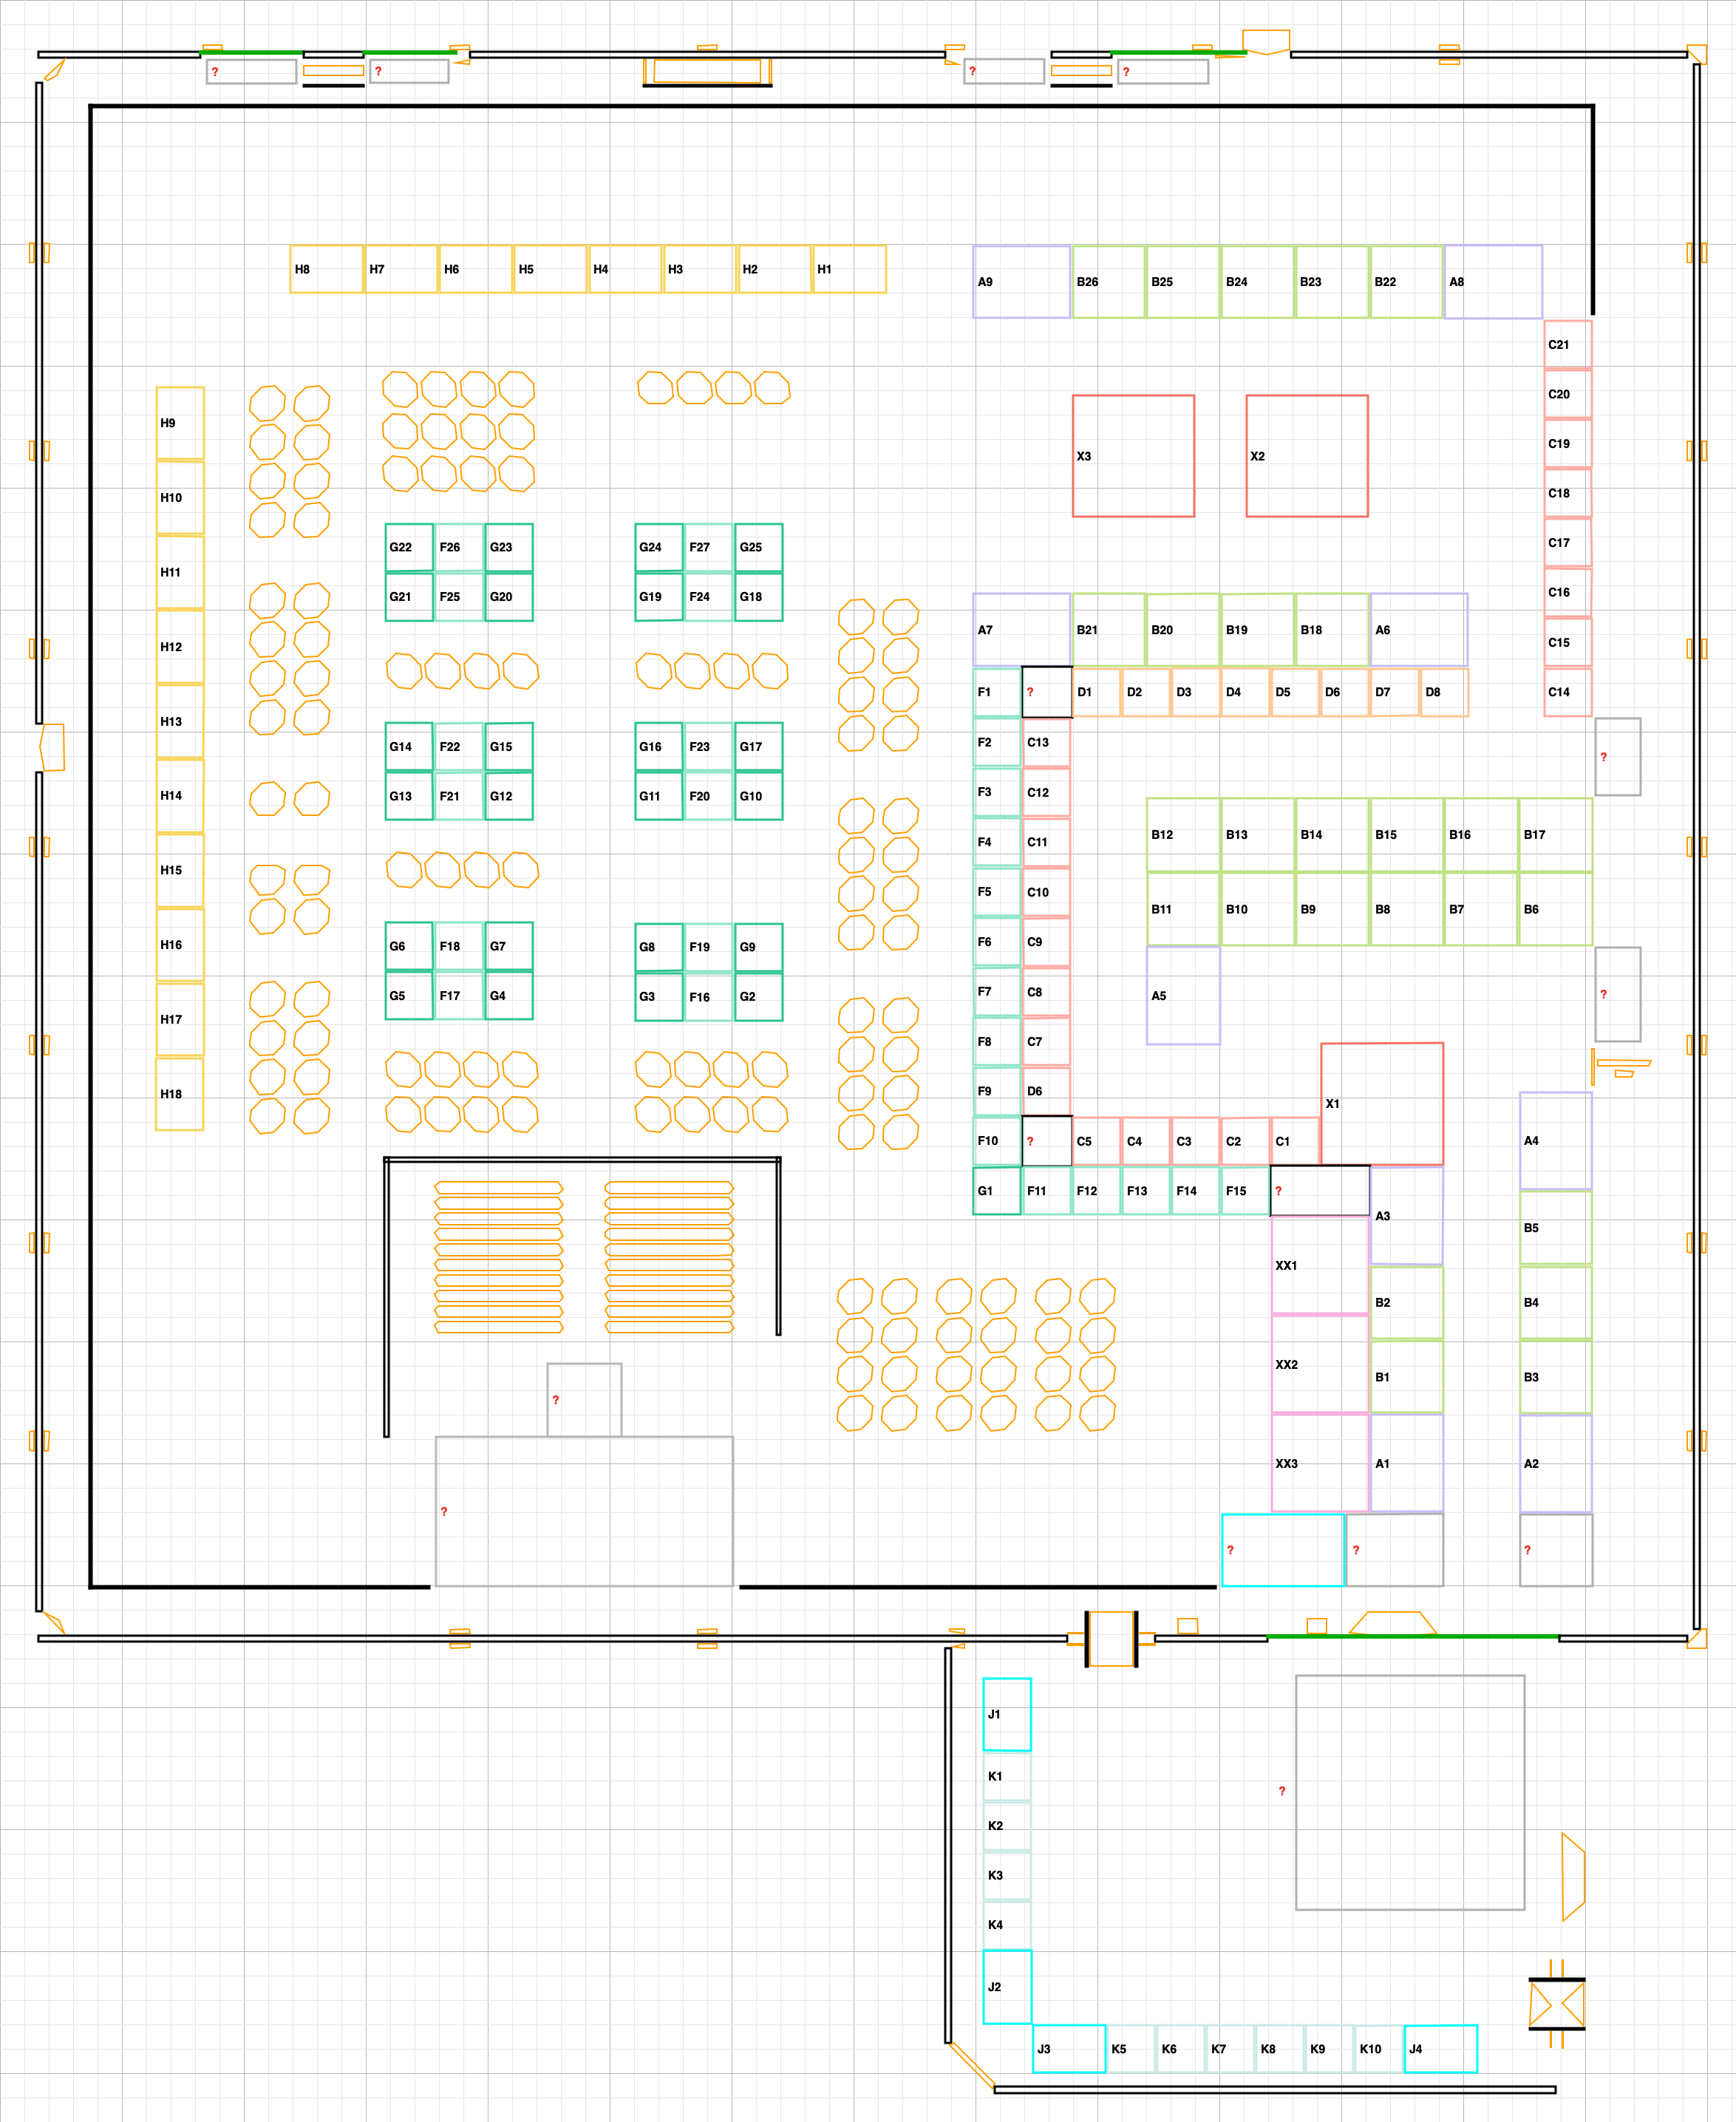

In [3]:
render("../output/swift4/plan1")  # layout.png


{
  "duplicate_ids": [],
  "gaps_in_numbering": {
    "F": [
      1
    ]
  },
  "ids_read": 208,
  "items_per_class": {
    "Booth A": 112,
    "Booth B": 30,
    "Booth C": 16,
    "Booth F": 42,
    "Interactive space I": 9,
    "Seating": 3,
    "Unlabeled block": 2,
    "object": 47,
    "wall": 16
  },
  "items_without_id": 69,
  "max_number_per_prefix": {
    "A": 112,
    "B": 30,
    "C": 16,
    "F": 42,
    "I": 9
  }
}


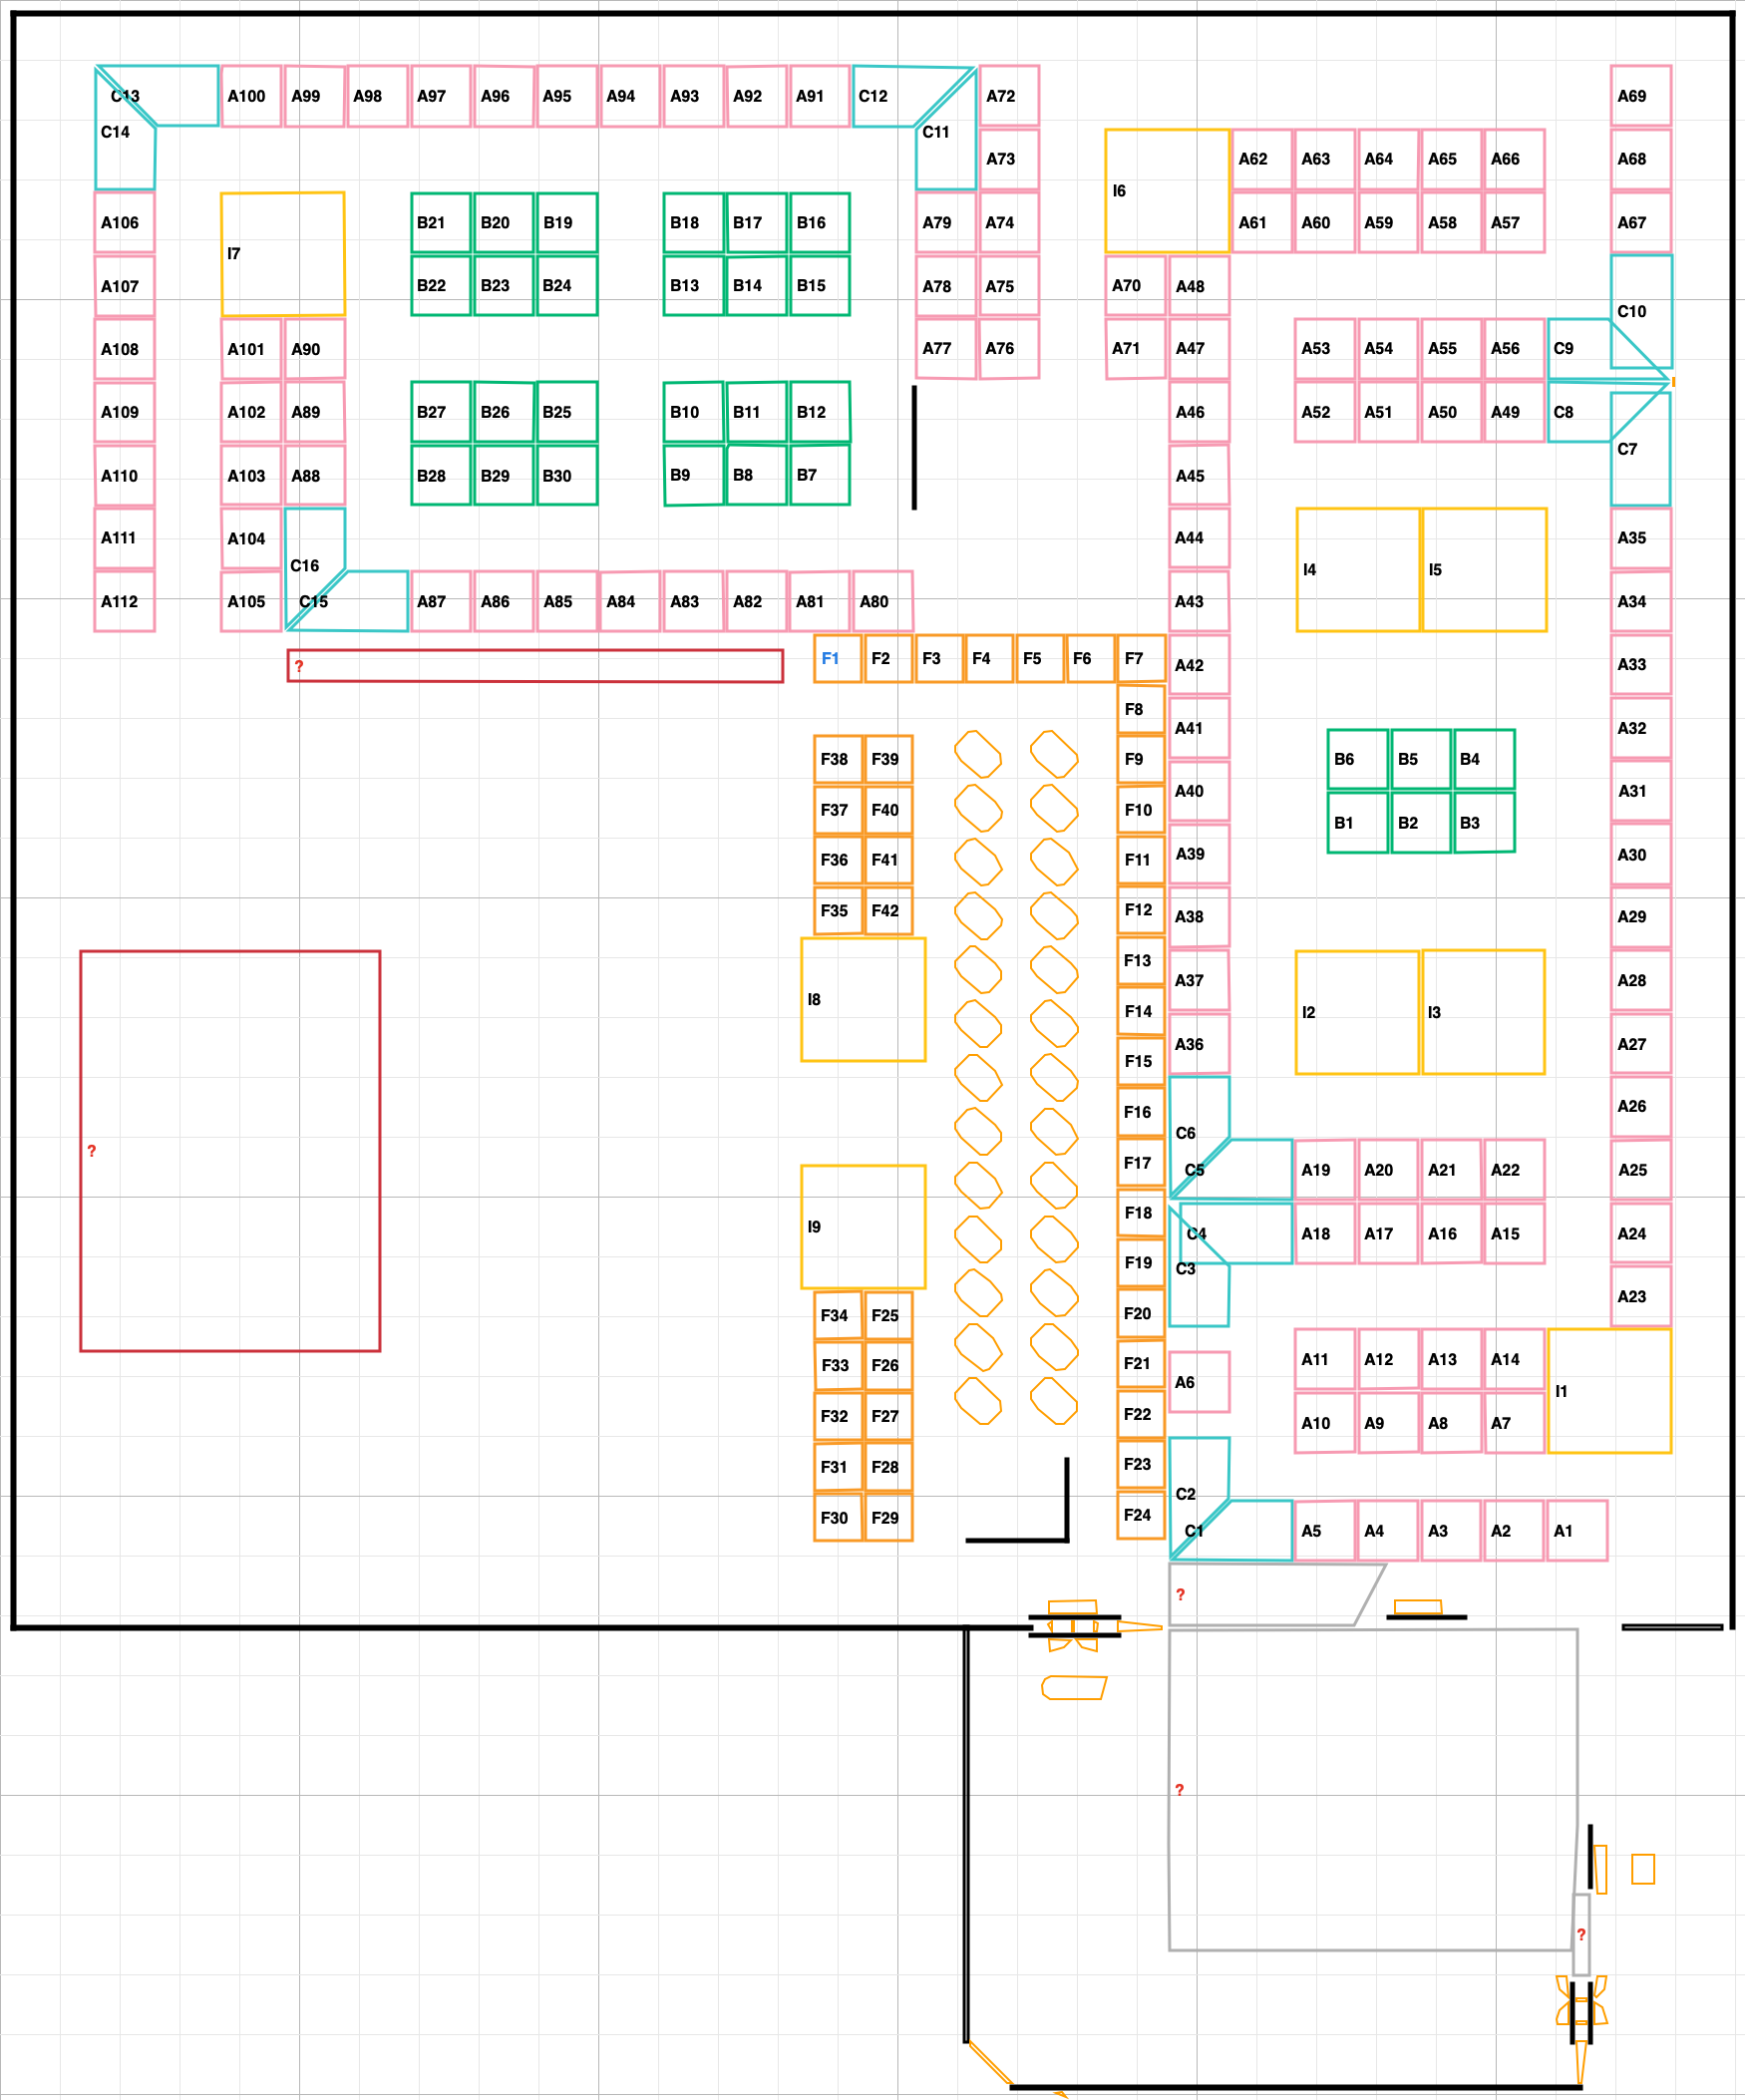

In [4]:
render("../output/swift4/plan2")  # layout_2.png


{
  "duplicate_ids": [],
  "gaps_in_numbering": {
    "H": [
      4,
      13,
      14,
      24,
      34,
      40,
      41,
      42,
      43,
      44,
      45,
      46,
      47,
      48,
      49,
      54,
      64,
      74,
      84
    ]
  },
  "ids_read": 67,
  "items_per_class": {
    "Booth H": 67,
    "Stage": 1,
    "Tenant space": 6,
    "object": 63,
    "pillar": 25,
    "wall": 14
  },
  "items_without_id": 109,
  "max_number_per_prefix": {
    "H": 86
  }
}


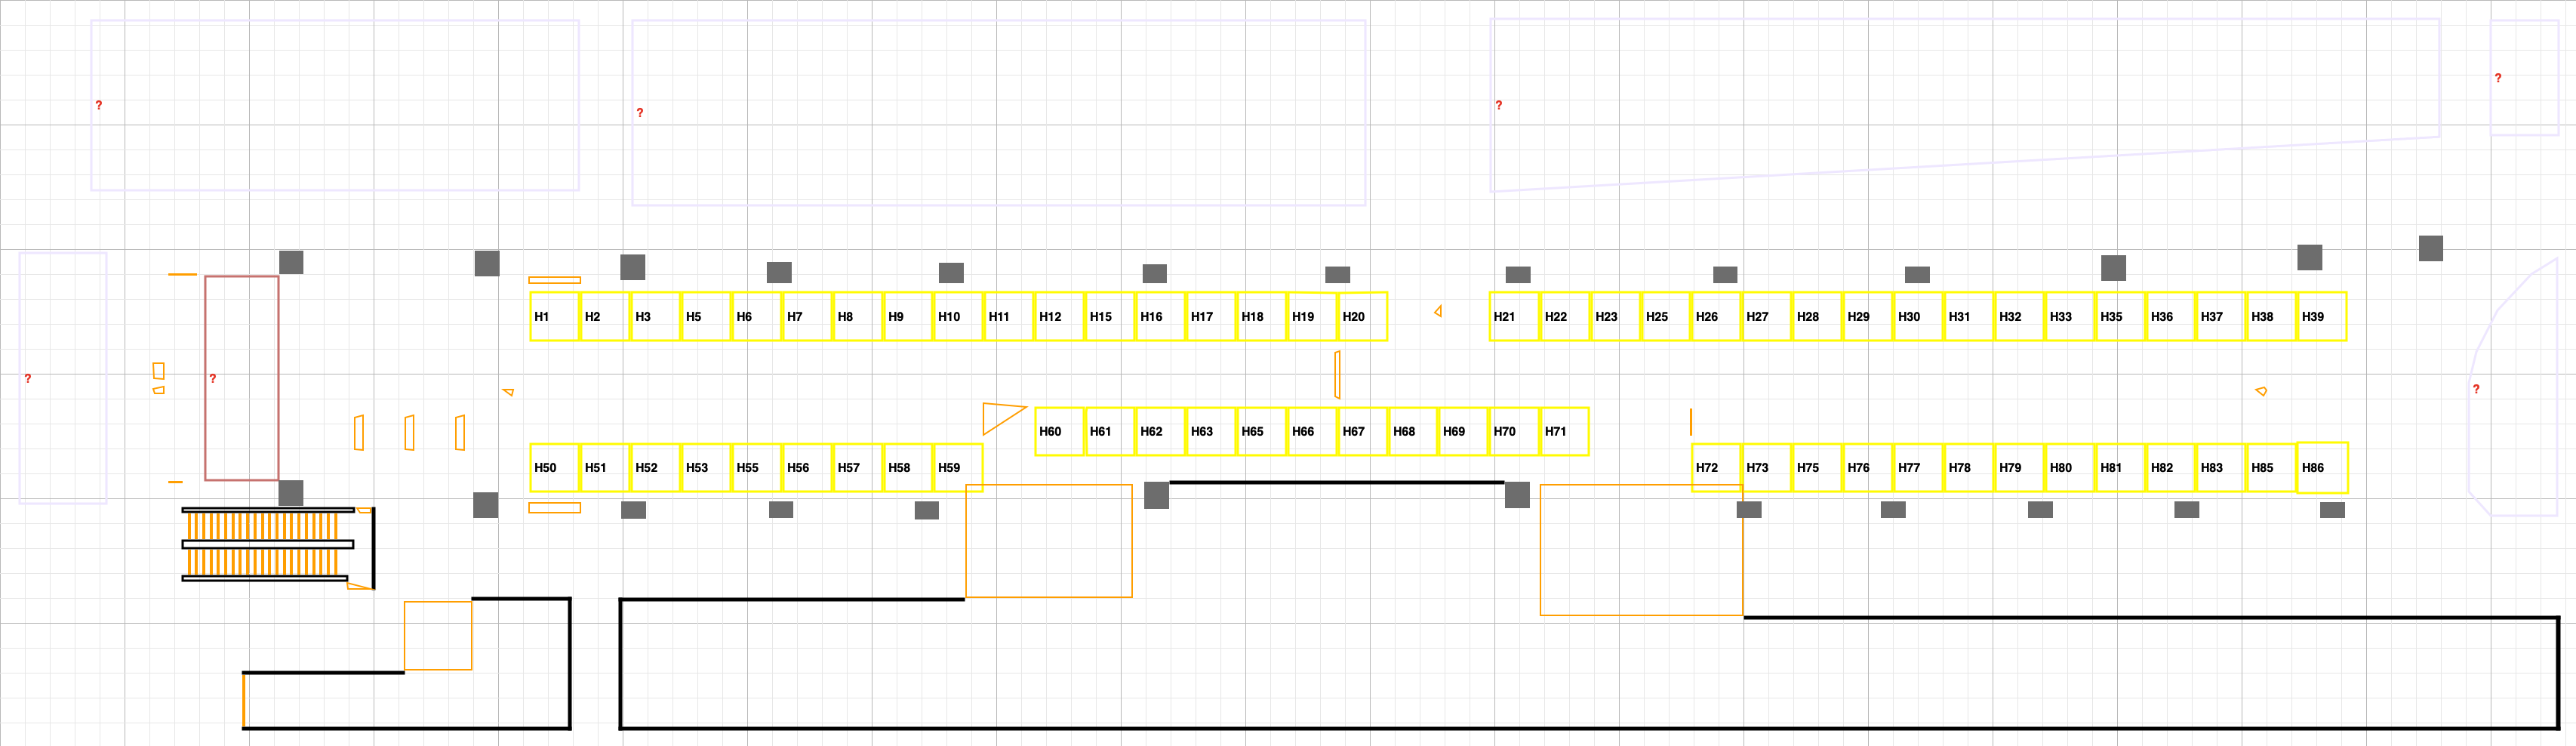

In [5]:
render("../output/swift4/plan3")  # layout_3.png
